# Intelligent House Price Prediction Using Ensemble Learning

## Project Team

1. Abubakar – Model Development  
2. Shivu – Data Preprocessing  
3. Dhanush – EDA & Visualization  
4. Nithing – Documentation  

Course: AI ENGINEER

Batch Id: 04-AUG-25-AEN-BUN-072-WDM0900-BAN


## Problem Statement

The objective of this project is to develop a robust machine learning system to predict house prices based on various property features.


## Methodology

1. Data Collection
2. Data Cleaning
3. Feature Engineering
4. Model Training
5. Evaluation
6. Recommendation System


# Importing Libraries 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor

import warnings
warnings.filterwarnings("ignore")


## 1. Dataset Loading

In this section, the Ames Housing dataset is loaded for analysis and modeling.


In [2]:
df=pd.read_csv("data/data.csv")
df.head()## 1. Dataset Loading

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Dataset Overview

This section provides basic information about the dataset including shape, data types, and summary statistics.


In [3]:
df.shape

(1460, 81)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 3. Missing Value Analysis

Missing values can affect model performance. This section identifies and handles missing data.


In [6]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [7]:
num_cols = df.select_dtypes(include=["int64","float64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

## 4. Exploratory Data Analysis

EDA helps in understanding relationships between features and target variable.


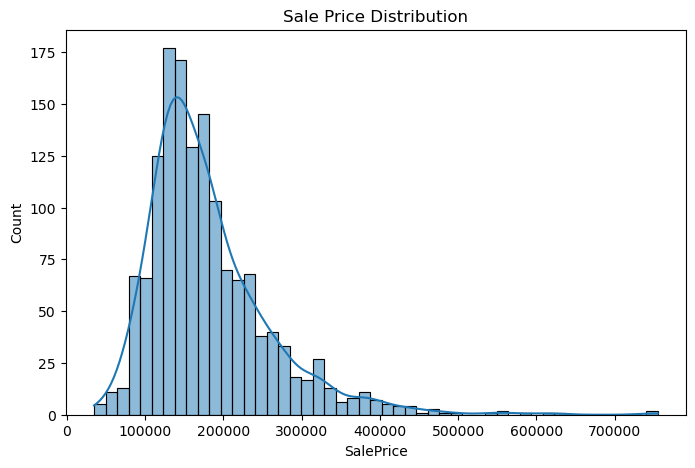

In [8]:
plt.figure(figsize=(8,5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Sale Price Distribution")
plt.show()

## 5. Feature Engineering

New features are created to improve model performance.


In [9]:
df["TotalSF"] = df["1stFlrSF"] + df["2ndFlrSF"] + df["TotalBsmtSF"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

## 6. Encoding Categorical Variables

Categorical features are converted into numerical format.


In [10]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])


## 7. Train-Test Split

Dataset is divided for training and testing.


In [11]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## 8. Feature Scaling

Standardization improves model convergence.


In [12]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


## 9. Model Training

Multiple regression models are trained and evaluated.


In [13]:
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "DecisionTree": DecisionTreeRegressor(),
    "RandomForest": RandomForestRegressor(random_state=42),
    "GradientBoost": GradientBoostingRegressor(random_state=42)
}

results = {}


In [14]:
for name, model in models.items():
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    
    results[name] = [rmse, r2]


## 10. Model Comparison

Performance of different models is compared.


In [15]:
comparison = pd.DataFrame(
    results,
    index=["RMSE","R2"]
).T

comparison.sort_values("R2", ascending=False)


,RMSE,R2
GradientBoost,28493.296233,0.894155
RandomForest,29968.836051,0.882908
Ridge,35332.393132,0.837246
Lasso,35342.048602,0.837157
Linear,35344.207069,0.837137
DecisionTree,40786.441674,0.783121


## Feature Importance Analysis


In [16]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(10)


OverallQual     0.386545
TotalSF         0.366647
2ndFlrSF        0.028584
YearBuilt       0.016823
LotArea         0.012393
HouseAge        0.011689
BsmtFinSF1      0.011210
GrLivArea       0.010816
YearRemodAdd    0.010335
LotFrontage     0.009624
dtype: float64

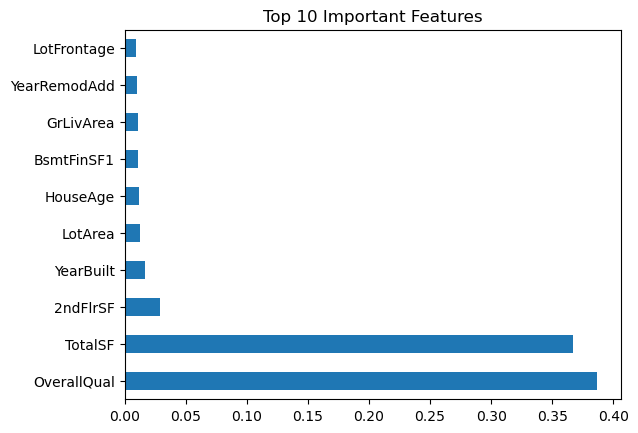

In [17]:
importance.head(10).plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()


## Hyperparameter Tuning


In [18]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators":[100,200],
    "max_depth":[10,20,None]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    params,
    cv=3,
    scoring="r2"
)

grid.fit(X_train, y_train)

grid.best_params_


{'max_depth': 10, 'n_estimators': 200}

## House Recommendation System


In [19]:
def recommend(budget, rooms):
    
    df_rec = df[
        (df["SalePrice"] <= budget) &
        (df["TotRmsAbvGrd"] >= rooms)
    ]
    
    return df_rec.sort_values("SalePrice").head(5)


## Future Scope

- Web-based deployment
- Mobile application
- Deep learning models
- Real-time market integration


## References

1. Kaggle Ames Housing Dataset  
2. Scikit-Learn Documentation  
3. Machine Learning – Tom Mitchell


## 11. Ensemble Learning

Ensemble techniques combine multiple models for better accuracy.


In [20]:
ensemble = VotingRegressor([
    ("rf", RandomForestRegressor()),
    ("gb", GradientBoostingRegressor()),
    ("lr", LinearRegression())
])

ensemble.fit(X_train, y_train)

pred = ensemble.predict(X_test)

np.sqrt(mean_squared_error(y_test, pred)), r2_score(y_test, pred)


(np.float64(28361.65255844237), 0.8951304919610733)

## 12. Challenges Faced

- High missing values
- High dimensionality
- Overfitting
- Encoding complexity
- Training time


## 13. Conclusion

The ensemble model achieved superior performance. Feature engineering and preprocessing played a vital role in improving prediction accuracy.
